
# EV Weight Simulation — Statistical Analysis

## Research Question
Does the modeled percentage increase in energy consumption
from adding 200 kg differ among passenger cars, SUVs,
and pickup trucks?

## Hypotheses
H0: All three vehicle groups have equal mean percentage increases.

H1: At least one vehicle group has a different mean percentage increase.

## Statistical Approach
- One-way ANOVA (subject to assumption checks)
- Significance level: 0.05
- Target power: 0.80
- Three vehicle groups


In [1]:

import pandas as pd

# Load the simulated experiment dataset
df = pd.read_csv("../data/ev_experiment.csv")

# Verify sample sizes
print(df.groupby("vehicle_group").size())
print(f"\nTotal sample size: {len(df)}")


vehicle_group
Passenger Cars    374
Pickup Trucks      90
SUVs              436
dtype: int64

Total sample size: 900



## Simulation Assumptions and Limitations

This computational experiment uses real EPA energy-consumption
data as reference baselines and a simplified rolling-resistance
model to estimate the effect of adding 200 kg to electric vehicles.

Assumptions:
- Added vehicle mass: 200 kg
- Rolling-resistance coefficient: 0.01
- Drivetrain efficiency: 90%
- Gravitational acceleration: 9.81 m/s²
- Flat-road, constant-speed conditions
- No changes in aerodynamics or regenerative braking
- The same absolute additional energy consumption is applied
  to every vehicle configuration

Limitations:
- The loaded vehicle outcomes are simulated, not measured.
- Vehicle-specific rolling resistance and efficiency are not modeled.
- The simulation does not represent a full real-world driving cycle.
- The statistical differences in percentage increases arise from
  differences in EPA baseline energy consumption.
- The model does not establish real-world causal differences
  in weight sensitivity across vehicle classes.
- Statistical confidence intervals do not account for uncertainty
  in the assumed physical parameters.
- Removing repeated make/model names does not guarantee
  complete independence among vehicle configurations.
- The power analysis assumes conventional equal-variance ANOVA,
  while the final hypothesis test uses Welch's ANOVA.



## Power Analysis

A sensitivity-based sample size analysis was conducted using
Cohen's conventional small, medium, and large effect sizes
for one-way ANOVA.

Parameters:
- Significance level (alpha): 0.05
- Target statistical power: 0.80
- Number of vehicle groups: 3
- Cohen's f: 0.10, 0.25, and 0.40

The purpose is to estimate the sample size required to
detect different magnitudes of group differences.

This is a planning/sensitivity analysis rather than a
preregistered sample size determination.


In [2]:

import numpy as np
import pandas as pd
from statsmodels.stats.power import FTestAnovaPower

# Power analysis assumptions
alpha = 0.05
target_power = 0.80
num_groups = 3

# Cohen's conventional effect sizes for ANOVA
effect_sizes = {
    "Small": 0.10,
    "Medium": 0.25,
    "Large": 0.40
}

# Initialize power analysis
power_analysis = FTestAnovaPower()

results = []

for label, effect_size in effect_sizes.items():

    # Calculate required total sample size
    required_n = power_analysis.solve_power(
        effect_size=effect_size,
        alpha=alpha,
        power=target_power,
        k_groups=num_groups
    )

    # Round up to a multiple of 3 for equal groups
    total_n = int(np.ceil(required_n / num_groups) * num_groups)

    results.append({
        "Effect Size": label,
        "Cohen's f": effect_size,
        "Total Sample Size": total_n,
        "Per Group": total_n // num_groups
    })

power_results = pd.DataFrame(results)

display(power_results)


,Effect Size,Cohen's f,Total Sample Size,Per Group
0,Small,0.10,969,323
1,Medium,0.25,159,53
2,Large,0.40,66,22



## Balanced Random Sampling

A stratified random sample of 180 EV configurations was
selected from the available 900 configurations.

The sample contains 60 passenger cars, 60 SUVs, and
60 pickup trucks.

A random seed of 42 was used to ensure reproducibility.
Sampling was performed without replacement within each group.


In [3]:

# Select 60 EV configurations from each vehicle group
sample_size_per_group = 60
random_seed = 42

balanced_df = (
    df.groupby("vehicle_group", group_keys=False)
      .sample(
          n=sample_size_per_group,
          random_state=random_seed,
          replace=False
      )
      .sort_values(["vehicle_group", "epa_id"])
      .reset_index(drop=True)
)

# Verify balanced sample
print(balanced_df.groupby("vehicle_group").size())
print(f"\nTotal sample size: {len(balanced_df)}")

# Save for reproducibility
balanced_df.to_csv("../data/ev_balanced_sample.csv", index=False)

# Verify balanced sample
print(balanced_df.groupby("vehicle_group").size())
print(f"\nTotal sample size: {len(balanced_df)}")

# Save for reproducibility
balanced_df.to_csv("../data/ev_balanced_sample.csv", index=False)

vehicle_group
Passenger Cars    60
Pickup Trucks     60
SUVs              60
dtype: int64

Total sample size: 180
vehicle_group
Passenger Cars    60
Pickup Trucks     60
SUVs              60
dtype: int64

Total sample size: 180


In [4]:
# Check for repeated vehicle models
model_counts = (
    balanced_df.groupby(["make", "model"])
    .size()
    .reset_index(name="count")
)

# Show models appearing more than once
repeated_models = model_counts[
    model_counts["count"] > 1
].sort_values("count", ascending=False)

print("Number of repeated make/model combinations:")
print(len(repeated_models))

print("\nRepeated models:")
display(repeated_models)

# Count observations associated with repeated models
print(
    "\nObservations belonging to repeated models:",
    repeated_models["count"].sum()
)

Number of repeated make/model combinations:
20

Repeated models:


,make,model,count
27,Ford,F-150 Lightning 4WD,3
30,Ford,F-150 Lightning 4WD Extended Range,3
32,Ford,F-150 Lightning Platinum 4WD,3
87,Porsche,Taycan 4S Cross Turismo,3
13,BMW,i4 M50 Gran Coupe (19 inch wheels),2
107,Rivian,R1T All-Terrain Dual Max (20in),2
136,Tesla,Model 3 Performance AWD,2
131,Subaru,Solterra AWD,2
118,Rivian,R1T Dual Standard (22in),2
113,Rivian,R1T Dual Large (22in),2



Observations belonging to repeated models: 44


In [5]:
# Count unique make/model combinations in each group
unique_models = df.drop_duplicates(
    subset=["vehicle_group", "make", "model"]
)

print("Available unique models by group:")
print(unique_models.groupby("vehicle_group").size())

Available unique models by group:
vehicle_group
Passenger Cars    200
Pickup Trucks      73
SUVs              279
dtype: int64


In [6]:
# Randomly select one record per make/model combination
unique_df = (
    df.sample(frac=1, random_state=42)
    .drop_duplicates(
        subset=["vehicle_group", "make", "model"]
    )
)

# Randomly select 60 unique models from each group
final_df = (
    unique_df.groupby("vehicle_group", group_keys=False)
    .sample(n=60, random_state=42)
    .sort_values(["vehicle_group", "make", "model"])
    .reset_index(drop=True)
)

# Verify sample sizes
print("Final sample sizes:")
print(final_df.groupby("vehicle_group").size())

# Check for repeated models
duplicates = final_df.duplicated(
    subset=["make", "model"]
).sum()

print(f"\nRepeated models: {duplicates}")
print(f"Total sample size: {len(final_df)}")

# Save final dataset
final_df.to_csv("../data/ev_final_sample.csv", index=False)

Final sample sizes:
vehicle_group
Passenger Cars    60
Pickup Trucks     60
SUVs              60
dtype: int64

Repeated models: 0
Total sample size: 180


## ANOVA Assumption Checks

We evaluate the distributions of modeled percentage increases
across vehicle groups before conducting hypothesis testing.

The analysis includes:
- Histograms to assess distribution shapes
- Shapiro-Wilk tests for normality
- Levene's test for equality of variances

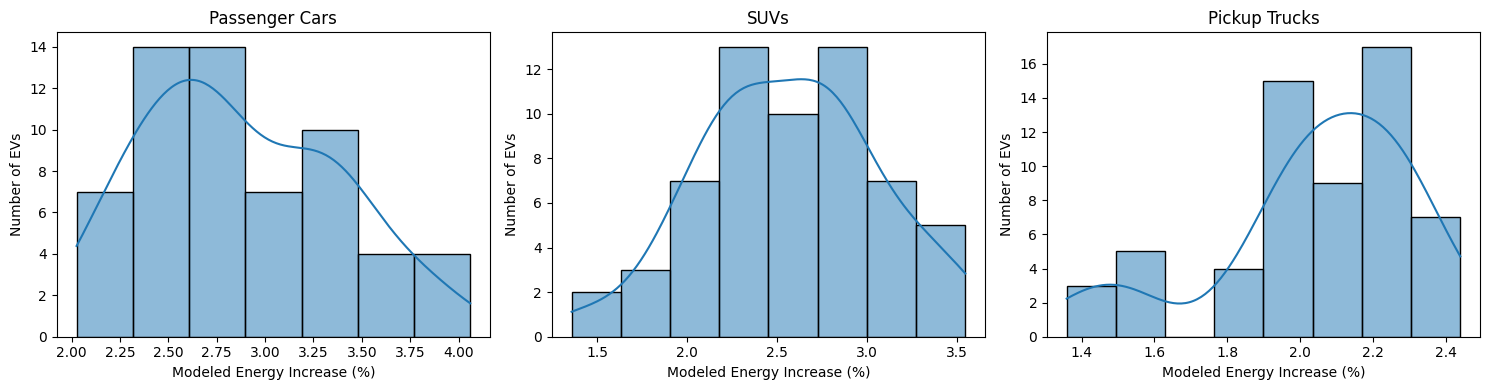

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

groups = ["Passenger Cars", "SUVs", "Pickup Trucks"]

for ax, group in zip(axes, groups):
    values = final_df.loc[
        final_df["vehicle_group"] == group,
        "percent_increase"
    ]

    sns.histplot(values, kde=True, ax=ax)
    ax.set_title(group)
    ax.set_xlabel("Modeled Energy Increase (%)")
    ax.set_ylabel("Number of EVs")

plt.tight_layout()
plt.show()

In [8]:
from scipy.stats import shapiro, levene

groups = ["Passenger Cars", "SUVs", "Pickup Trucks"]

group_data = [
    final_df.loc[
        final_df["vehicle_group"] == group,
        "percent_increase"
    ].values
    for group in groups
]

# Normality tests
print("Shapiro-Wilk normality tests:")

for group, values in zip(groups, group_data):
    stat, p = shapiro(values)
    print(f"{group}: W={stat:.4f}, p={p:.4f}")

# Equal variance test
stat, p = levene(*group_data, center="median")

print(f"\nLevene's test: statistic={stat:.4f}, p={p:.4f}")

Shapiro-Wilk normality tests:
Passenger Cars: W=0.9675, p=0.1103
SUVs: W=0.9878, p=0.8123
Pickup Trucks: W=0.8933, p=0.0001

Levene's test: statistic=12.6860, p=0.0000



## Welch's One-Way ANOVA

Levene's test indicated unequal variances across vehicle
groups (p < 0.001).

Shapiro-Wilk testing also identified a departure from
normality in the pickup truck group.

Welch's ANOVA was selected to compare the mean modeled
percentage increases across passenger cars, SUVs, and
pickup trucks because it does not assume equal variances.


In [9]:

from statsmodels.stats.oneway import anova_oneway

# Welch's ANOVA
welch_result = anova_oneway(
    data=final_df["percent_increase"],
    groups=final_df["vehicle_group"],
    use_var="unequal"
)

print(welch_result)


AnovaResult(statistic=np.float64(73.65728718213688), pvalue=np.float64(6.903717722723723e-21), df=(2.0, np.float64(107.7357608397438)), df_num=2.0, df_denom=np.float64(107.7357608397438), nobs_total=np.float64(180.0), n_groups=3, means=array([2.87630128, 2.04479357, 2.56406854]), nobs=array([60., 60., 60.]), vars_=array([0.25337581, 0.07462897, 0.24290295]), use_var='unequal', welch_correction=True, df2=None, df_num2=None, pvalue2=None)


In [10]:

from scipy.stats import studentized_range
import numpy as np
import pandas as pd

# Group summary statistics
summary = final_df.groupby("vehicle_group")["percent_increase"].agg(
    ["mean", "var", "count"]
)

groups = summary.index.tolist()
k = len(groups)
results = []

for i in range(k):
    for j in range(i + 1, k):
        group1 = groups[i]
        group2 = groups[j]

        mean_diff = summary.loc[group1, "mean"] - summary.loc[group2, "mean"]

        v1 = summary.loc[group1, "var"] / summary.loc[group1, "count"]
        v2 = summary.loc[group2, "var"] / summary.loc[group2, "count"]

        se = np.sqrt(v1 + v2)

        # Welch-Satterthwaite degrees of freedom
        df_welch = (v1 + v2)**2 / (
            v1**2 / (summary.loc[group1, "count"] - 1)
            + v2**2 / (summary.loc[group2, "count"] - 1)
        )

        # Games-Howell statistic and adjusted p-value
        q = np.sqrt(2) * abs(mean_diff) / se
        p_adjusted = studentized_range.sf(q, k, df_welch)

        results.append({
            "Group 1": group1,
            "Group 2": group2,
            "Mean Difference": mean_diff,
            "Adjusted p-value": p_adjusted
        })

games_howell_results = pd.DataFrame(results)

display(games_howell_results)


,Group 1,Group 2,Mean Difference,Adjusted p-value
0,Passenger Cars,Pickup Trucks,0.831508,1.088019e-14
1,Passenger Cars,SUVs,0.312233,2.359134e-03
2,Pickup Trucks,SUVs,-0.519275,6.377749e-10



## Observed Effect Size

Eta-squared is calculated to describe the proportion of
variation in modeled percentage energy increases associated
with differences between vehicle groups.

This descriptive effect size is separate from Cohen's f = 0.25,
which was assumed for the earlier power analysis.


In [11]:

# Calculate observed eta-squared

grand_mean = final_df["percent_increase"].mean()

group_stats = final_df.groupby("vehicle_group")[
    "percent_increase"
].agg(["mean", "count"])

# Variation explained by differences between groups
ss_between = (
    group_stats["count"] *
    (group_stats["mean"] - grand_mean) ** 2
).sum()

# Total variation in the dataset
ss_total = (
    (final_df["percent_increase"] - grand_mean) ** 2
).sum()

# Eta-squared
eta_squared = ss_between / ss_total

print(f"Observed eta-squared: {eta_squared:.4f}")
print(f"Percentage of variation associated with vehicle class: {eta_squared * 100:.2f}%")


Observed eta-squared: 0.3859
Percentage of variation associated with vehicle class: 38.59%



## 95% Confidence Intervals

We calculate 95% confidence intervals for the mean modeled
percentage increase in each vehicle group.

The intervals use the Student's t-distribution and the
sample standard error for each group.

These intervals describe sampling uncertainty under the
assumption that observations are independent. They do not
account for uncertainty in the simulation's physical parameters.


In [12]:

import numpy as np
import pandas as pd
from scipy.stats import t

# Calculate group summary statistics
ci_results = (
    final_df.groupby("vehicle_group")["percent_increase"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

# Standard error of each group mean
ci_results["se"] = (
    ci_results["std"] / np.sqrt(ci_results["count"])
)

# Critical t-value for 95% confidence intervals
ci_results["t_critical"] = t.ppf(
    0.975,
    df=ci_results["count"] - 1
)

# Margin of error
ci_results["margin_error"] = (
    ci_results["t_critical"] * ci_results["se"]
)

# Confidence interval bounds
ci_results["ci_lower"] = (
    ci_results["mean"] - ci_results["margin_error"]
)

ci_results["ci_upper"] = (
    ci_results["mean"] + ci_results["margin_error"]
)

display(
    ci_results[
        ["vehicle_group", "count", "mean",
        "ci_lower", "ci_upper"]
    ].round(3)
)


,vehicle_group,count,mean,ci_lower,ci_upper
0,Passenger Cars,60,2.876,2.746,3.006
1,Pickup Trucks,60,2.045,1.974,2.115
2,SUVs,60,2.564,2.437,2.691


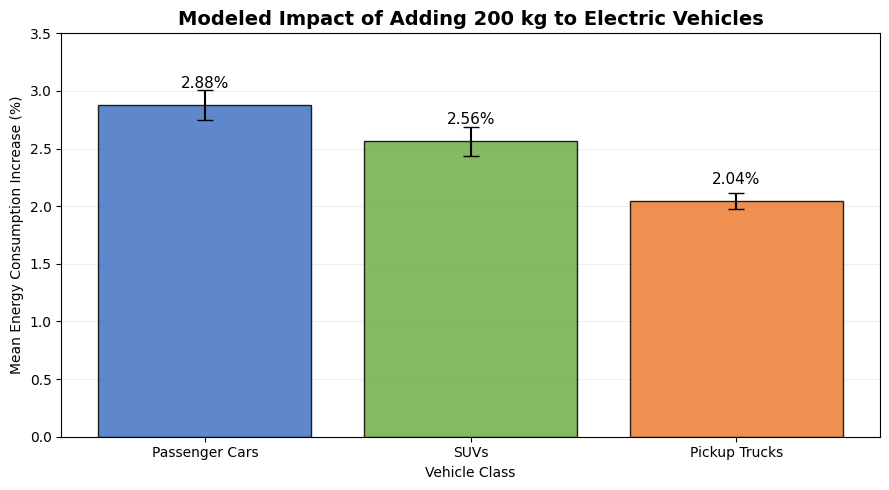

In [13]:

import matplotlib.pyplot as plt

# Set the order of the vehicle groups
order = ["Passenger Cars", "SUVs", "Pickup Trucks"]

plot_df = (
    ci_results.set_index("vehicle_group")
    .loc[order]
)

# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    plot_df.index,
    plot_df["mean"],
    yerr=plot_df["margin_error"],
    capsize=6,
    color=["#4472C4", "#70AD47", "#ED7D31"],
    edgecolor="black",
    alpha=0.85
)

# Add mean labels
for bar, mean in zip(bars, plot_df["mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{mean:.2f}%",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "Modeled Impact of Adding 200 kg to Electric Vehicles",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Mean Energy Consumption Increase (%)")
ax.set_xlabel("Vehicle Class")
ax.set_ylim(0, 3.5)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save figure for report and presentation
plt.savefig(
    "../ev_weight_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

import numpy as np

# Simulation assumptions
added_mass = 200
crr = 0.01
gravity = 9.81
efficiency = 0.90

# Expected additional energy consumption
expected_increase = (
    crr * added_mass * gravity / (3.6 * efficiency)
)

print(f"Expected increase: {expected_increase:.4f} Wh/km")

# Verify simulated values
actual_increase = (
    final_df["loaded_wh_km"] - final_df["wh_per_km"]
)

print(
    "Actual mean increase:",
    round(actual_increase.mean(), 4),
    "Wh/km"
)

print(
    "All increases match model:",
    np.allclose(actual_increase, expected_increase)
)

# Verify percentage increase formula
expected_percent = (
    actual_increase / final_df["wh_per_km"] * 100
)

print(
    "Percentage calculations correct:",
    np.allclose(
        final_df["percent_increase"],
        expected_percent
    )
)


Expected increase: 6.0556 Wh/km
Actual mean increase: 6.0556 Wh/km
All increases match model: True
Percentage calculations correct: True


In [15]:

# Verify final sample
print("Total observations:", len(final_df))

print("\nObservations per group:")
print(final_df.groupby("vehicle_group").size())

print("\nRepeated make/model combinations:")
print(
    final_df.duplicated(
        subset=["make", "model"]
    ).sum()
)

print("\nMissing percentage values:")
print(final_df["percent_increase"].isna().sum())


Total observations: 180

Observations per group:
vehicle_group
Passenger Cars    60
Pickup Trucks     60
SUVs              60
dtype: int64

Repeated make/model combinations:
0

Missing percentage values:
0
